# Projet Leyenda - Livrable 1
##### *Par Noah.V, Noah.M, Hugo.L*

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:

![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- Le deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Nous avons déjà réalisé le premier livrable avec différentes architectures, mais aussi différentes résolutions et comme on a pu le voir dans ce précédent livrable, les images redimensionné peuvent avoir du bruit ou être floue. C'est pour cela que dans ce ***deuxième livrable***, le but sera d'améliorer la clarté de ses images et permettre au modèle de mieux comprendre les images pour une meilleure detection.

Détail du ***Livrable 2:***
- Le code de chargement du fichier
- Le code du débruitage sur un sous-ensemble d'images bruitées. Le code doit être accompagné d'explications.
- Une étude de cas.

## Importation des librairies

In [26]:
%pip install -r requirements.txt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import plotly.express as px
from DL_dataset import *
from plotly.subplots import make_subplots
import plotly.graph_objects as go

Note: you may need to restart the kernel to use updated packages.


## Etape 1 : Chargement des images

Pour charger les differentes images de ce livrable 2, comme au livrable 1. Nous avons crée un script relier à *DL_datatset.py* qui a pour but de télécharger et préprocess les images automatiquements. Ensuite nous chargons les images dans les deux datasets train et test.

### Téléchargement du dataset

In [5]:
folder_raw = Path(f"./data")

if not os.path.exists(folder_raw):
    step_DL, step_unzip = True, True
    os.makedirs(folder_raw)
elif Path(folder_raw).exists() and len(os.listdir(folder_raw)) == 0:
    step_DL, step_unzip = True, True
else:
    step_DL, step_unzip = False, False

urls=[
    "https://drive.google.com/file/d/1Cp-x-Sc7wUzipu1GysZXx9g4Y2jrpIka/view?usp=sharing",
]

if step_DL==True:
    print("File download:")
    for link in urls:
        download_file(link,folder_raw)

if step_unzip==True:
    Get_file(folder_raw)

### Chargements des variables et Hyperparametres.

Ses différentes valeurs seront utilisés tout au long de ce notebook pour les models.

In [53]:
BATCH_SIZE = 16
IMG_SIZE = (256,256) 
train_split = 0.8
test_split = 0.2 
EPOCHS=200
noise_value= 0.1 #valeur pour definir l'ajout du bruit plus c'est grand, plus c'est un bruit fort


### Répartition des images

Due aux nombres limités d'images disponibles, nous décidons de partir sur une répartition 80/20.

In [54]:
dataset_raw = Path(f"./data/dataset/")

train_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=1 - train_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="training",
    seed=42
)

test_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=test_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="validation",
    seed=42
)



Found 148 files.
Using 119 files for training.
Found 148 files.
Using 29 files for validation.


In [55]:
def train_preprocess(image):
    image = image / 255.0
    
    actual_batch_size = tf.shape(image)[0]
    dynamic_patch_size = tf.stack([actual_batch_size, 128, 128, 3])
    
    image = tf.image.random_crop(image, size=dynamic_patch_size)
    
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    
    noise = tf.random.normal(shape=tf.shape(image), mean=0.0, stddev=noise_value)
    noisy_image = tf.clip_by_value(image + noise, 0.0, 1.0)
    
    return noisy_image,image

def val_preprocess(image):
    image = image / 255.0
    
    image = tf.image.resize(image, [128, 128])
    
    noise = tf.random.normal(shape=tf.shape(image), mean=0.0, stddev=noise_value)
    noisy_image = tf.clip_by_value(image + noise, 0.0, 1.0)
    
    return noisy_image,image

AUTOTUNE = tf.data.experimental.AUTOTUNE

train_set = train_set.map(train_preprocess, num_parallel_calls=AUTOTUNE)
test_set = test_set.map(val_preprocess, num_parallel_calls=AUTOTUNE)

train_set = train_set.prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

### Affichage des images

Pour confirmer le chargement des images et que les images ont bien été séparé entre le *test set* et le *train set*.

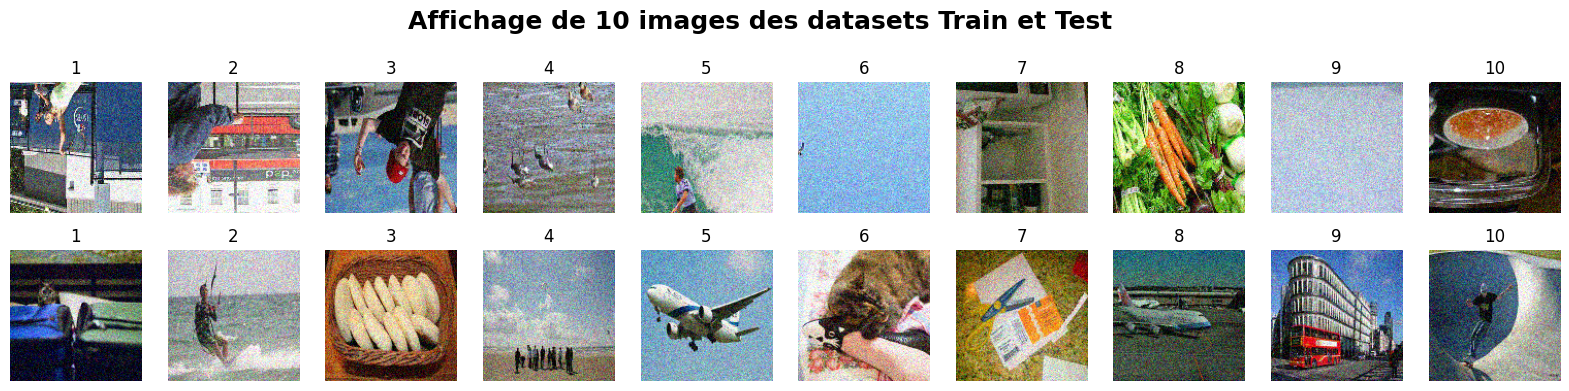

In [21]:
n = 10

#Affichage partie Trai,
plt.figure(figsize=(20, 4))
for images, _ in train_set.take(1):
    for i in range(n):
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(f'{i+1}')
        plt.axis("off")

#Affichage partie Test
for images, _ in test_set.take(1):
    for i in range(n):
        ax = plt.subplot(2, n, i + 1+n)
        plt.title("Image dans le set de Test")
        plt.imshow(images[i].numpy())
        plt.title(f'{i+1}')
        plt.axis("off") 

plt.suptitle("Affichage de 10 images des datasets Train et Test", fontsize=18, fontweight='bold', y=1.05)
plt.show() 

## Etape 2 : Code pour le débruitage

On initialise le modele, le DAE est un autoencoder, spécialisé pour le denoising des images.

In [23]:
"""
Input
"""

input_img = Input(shape=(128, 128, 3))

"""
Partie encodage
"""

x = Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D(pool_size=(2, 2), padding='same')(x)

x = Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same')(x)
encoded = MaxPooling2D(pool_size=(2, 2), padding='same')(x)

"""
Partie Décodage
"""

x = Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same')(encoded)
x = UpSampling2D(size=(2, 2))(x)

x = Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same')(x)
x = UpSampling2D(size=(2, 2))(x)

"""
Output
"""

decoded = Conv2D(filters=3, kernel_size=(3, 3), activation='sigmoid', padding='same')(x)


In [27]:
autoencoder = Model(inputs=input_img, outputs=decoded)
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

Ajout d'un early-stopping  et entrainement du modele.

In [29]:
early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', 
        patience=15, 
        restore_best_weights=True 
    )

history = autoencoder.fit(
    train_set,
    epochs=EPOCHS,
    validation_data=test_set,
    callbacks=[early_stop]
)

Epoch 1/200


C:\Users\hmjhl\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - loss: 0.0659 - val_loss: 0.0491
Epoch 2/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0389 - val_loss: 0.0256
Epoch 3/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.0223 - val_loss: 0.0175
Epoch 4/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0171 - val_loss: 0.0154
Epoch 5/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0161 - val_loss: 0.0130
Epoch 6/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.0137 - val_loss: 0.0121
Epoch 7/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0130 - val_loss: 0.0107
Epoch 8/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0119 - val_loss: 0.0102
Epoch 9/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.0124 - val_loss: 0.0099
Epoch 10/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - loss: 0.0108 - val_loss: 0.0105
Epoch 11/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.0105 - val_loss: 0.0093
Epoch 12/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - loss: 0.0100 - val_loss: 0.0089
E

### Sauvegarde du modèle

In [ ]:
if not os.path.exists("Model"):
    os.makedirs("Model")
autoencoder.save(f"Model/DAE_noise_{noise_value}.keras")

### Affichage comparaison entre l'image d'origine, bruité et débruité

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step


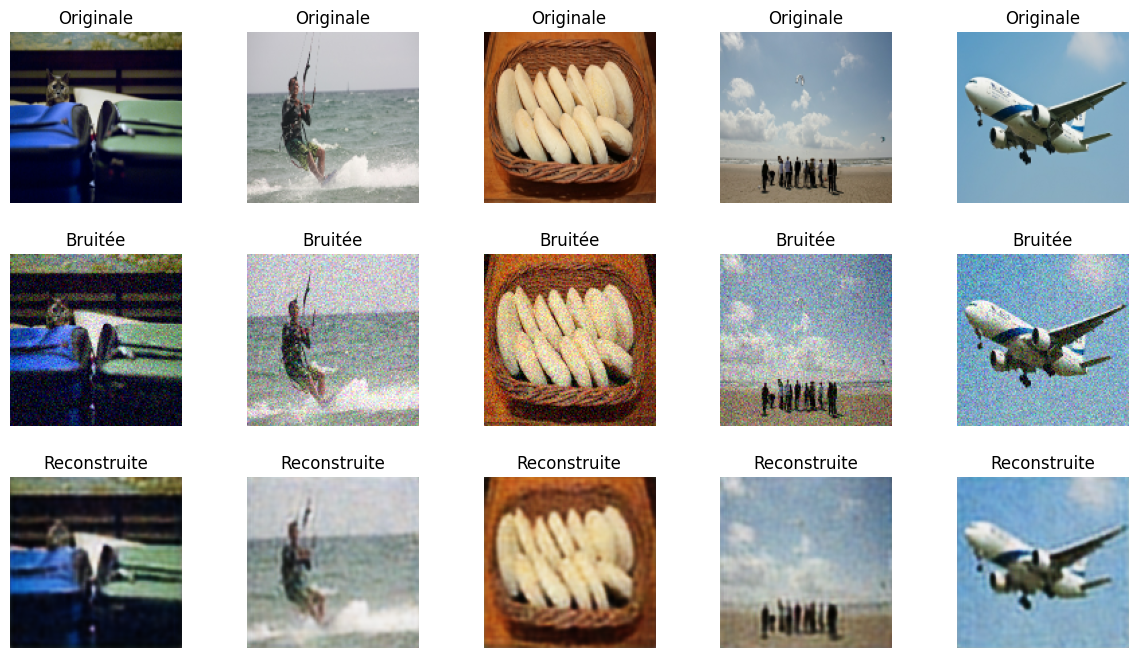

In [33]:
test_batch_noisy, test_batch_clean = next(iter(test_set.take(1)))
decoded_imgs = autoencoder.predict(test_batch_noisy)

n = min(5, BATCH_SIZE)  

plt.figure(figsize=(15, 8))
for i in range(n):
    # Original (clean)
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(test_batch_clean[i].numpy())
    plt.title("Originale")
    plt.axis('off')

    # Noisy
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(test_batch_noisy[i].numpy())
    plt.title("Bruitée")
    plt.axis('off')

    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(decoded_imgs[i])
    plt.title("Reconstruite")
    plt.axis('off')

plt.subplots_adjust(wspace=0.1, hspace=0.3)
plt.show()

Comparaison avec un noise de 0.3

Found 148 files.
Using 119 files for training.
Found 148 files.
Using 29 files for validation.


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,651 (295.51 KB)

 Trainable params: 75,651 (295.51 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200


C:\Users\hmjhl\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - loss: 0.0577 - val_loss: 0.0207
Epoch 2/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0216 - val_loss: 0.0167
Epoch 3/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0135 - val_loss: 0.0104
Epoch 4/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.0105 - val_loss: 0.0094
Epoch 5/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0100 - val_loss: 0.0086
Epoch 6/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.0092 - val_loss: 0.0075
Epoch 7/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.0084 - val_loss: 0.0074
Epoch 8/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 0.0084 - val_loss: 0.0071
Epoch 9/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0080 - val_loss: 0.0070
Epoch 10/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0077 - val_loss: 0.0068
Epoch 11/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0078 - val_loss: 0.0067
Epoch 12/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0077 - val_loss: 0.0067
E

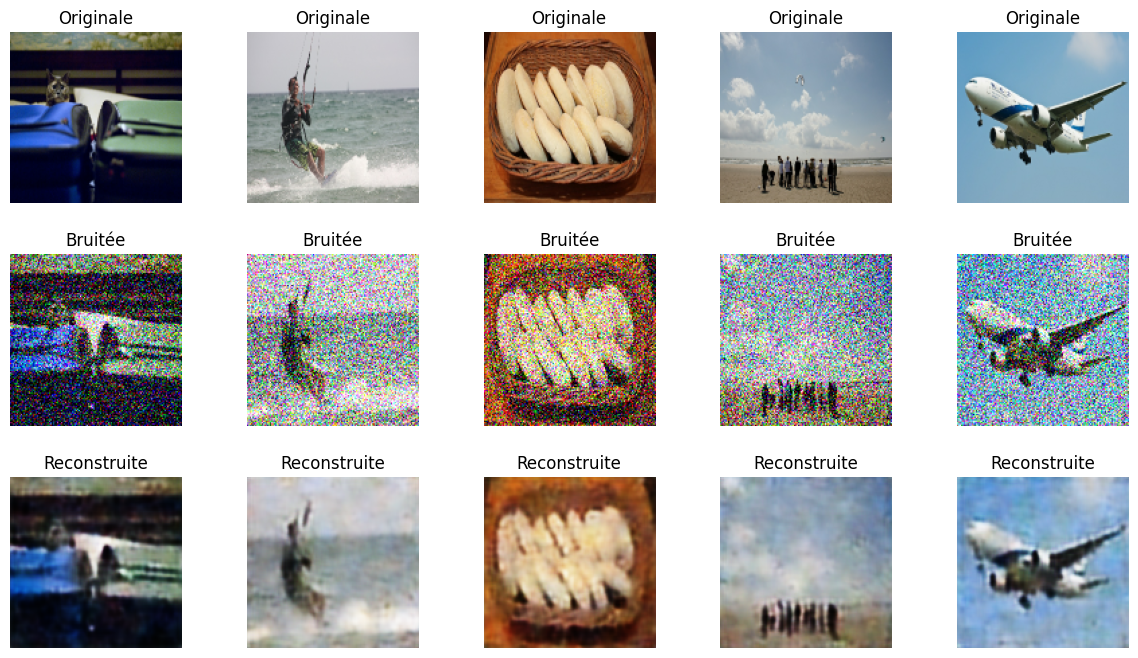

In [56]:
noise_value=0.3
train_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=1 - train_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="training",
    seed=42
)

test_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=test_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="validation",
    seed=42
)
AUTOTUNE = tf.data.experimental.AUTOTUNE

train_set = train_set.map(train_preprocess, num_parallel_calls=AUTOTUNE)
test_set = test_set.map(val_preprocess, num_parallel_calls=AUTOTUNE)

train_set = train_set.prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

Dae = Model(inputs=input_img, outputs=decoded)
Dae.compile(optimizer='adam', loss='mse')
Dae.summary()

early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', 
        patience=15, 
        restore_best_weights=True 
    )

history = Dae.fit(
    train_set,
    epochs=EPOCHS,
    validation_data=test_set,
    callbacks=[early_stop]
)

if not os.path.exists("Model"):
    os.makedirs("Model")
Dae.save(f"Model/DAE_noise_{noise_value}.keras")

test_batch_noisy, test_batch_clean = next(iter(test_set.take(1)))
decoded_imgs = Dae.predict(test_batch_noisy)

n = min(5, BATCH_SIZE)  

plt.figure(figsize=(15, 8))
for i in range(n):
    # Original (clean)
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(test_batch_clean[i].numpy())
    plt.title("Originale")
    plt.axis('off')

    # Noisy
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(test_batch_noisy[i].numpy())
    plt.title("Bruitée")
    plt.axis('off')

    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(decoded_imgs[i])
    plt.title("Reconstruite")
    plt.axis('off')

plt.subplots_adjust(wspace=0.1, hspace=0.3)
plt.show()

### Etude du modèle et des résultats

On peut voir que plus la valeur du bruit est haute, plus l'image devient "pixelisé" même si l'on reconnait les élements principaux.

## Etape 3 : Etude de cas

### Comparaisson des différents modèles utilisés 

Pour ce projet, nous avons essayé d'utiliser plusieurs auto encoder differents, comme l'auto-encoder traditionnel, le VAE, le CAE, le DAE, CVAE...
Cependant plusieurs d'entre eux avaient des résultats qu'ils nous convenaient pas ou avaient des contraintes trop importantes pour être sélectionné. Comme l'auto encoder traditionnel qui...